# MileStone 2
### This notebook will be divided into 5 sections
#### - A Data Audit
#### - Data Cleaning and Preprocessing
#### - Train/Test Split
#### - Baseline Model and Evaluation
#### - Conclusion and Next Steps

**Data Audit**

First I will import the data and complete the data audit.
The purpose of this audit is to investigate data types, missing values, duplicate records, invalid values, outliers and the target variable (Revenue).

In [1]:
import pandas as pd  

In [2]:
df = pd.read_csv("Data/online_shoppers_intention.csv")

In [3]:
df.shape # This inspects the dimensions i.e. how many sessions and how many variables

(12330, 18)

In [4]:
df.head() # This displays the first 5 entries 

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
df.sample(5, random_state=42) # This displays 5 completely random entries

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
8916,3,142.500000,0,0.00,48,1052.255952,0.004348,0.013043,0.000000,0.0,Nov,1,8,6,11,Returning_Visitor,False,False
772,6,437.391304,2,235.55,83,2503.881781,0.002198,0.004916,2.086218,0.0,Mar,2,2,3,2,Returning_Visitor,False,True
12250,1,41.125000,0,0.00,126,4310.004668,0.000688,0.012823,3.451072,0.0,Nov,2,2,2,2,Returning_Visitor,False,False
7793,2,141.000000,0,0.00,10,606.666667,0.008333,0.026389,36.672294,0.0,Aug,2,5,7,4,Returning_Visitor,False,False
6601,18,608.140000,6,733.80,168,4948.398759,0.006632,0.013528,10.150644,0.0,Aug,2,2,3,1,Returning_Visitor,True,False


In [6]:
df.info() # This gives us all variables and their data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [7]:
df.describe(include="all").T  # This gives us summary statistics for all the variables

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


#### What this tells us so far
So far we have successfully imported the dataset.
Upon initial inspection, we can see that the dataset contains 12330 observations and 18 variables. 
The variables are divided as follows:
- 7 Integer Variables
- 7 Floating Point Variables
- 2 Object Variables
- 2 Boolean Variables

Some of the integer variables, such as `Browser`, `Region`, `OperatingSystems` and `TrafficType`, represent categorical informaion not continuous numerical measurements.

So far we can also see their are no null entries which suggests there is no missing values displayed as NaN.

From the summary statistics, we can see that some of the variables could contain outliers, e.g. `ProductRelated_Duration` has a max of 63,973.5 and a median of 598.94. We will need to investigate this further.

We can also see that our target variable `Revenue` is imbalance, with 10,422 sessions not resulting in a purchase and 1,908 sessions resulting in a purchase. We will need to consider this during model evaluation.

In [8]:
df.isna().mean().sort_values(ascending=False)

Administrative             0.0
Administrative_Duration    0.0
Weekend                    0.0
VisitorType                0.0
TrafficType                0.0
Region                     0.0
Browser                    0.0
OperatingSystems           0.0
Month                      0.0
SpecialDay                 0.0
PageValues                 0.0
ExitRates                  0.0
BounceRates                0.0
ProductRelated_Duration    0.0
ProductRelated             0.0
Informational_Duration     0.0
Informational              0.0
Revenue                    0.0
dtype: float64

All variables returned 0.00.

This means that no missing values were detected.

In [9]:
df.nunique().sort_values() # This shows the number of unique values in each column

Revenue                       2
Weekend                       2
VisitorType                   3
SpecialDay                    6
OperatingSystems              8
Region                        9
Month                        10
Browser                      13
Informational                17
TrafficType                  20
Administrative               27
ProductRelated              311
Informational_Duration     1258
BounceRates                1872
PageValues                 2704
Administrative_Duration    3335
ExitRates                  4777
ProductRelated_Duration    9551
dtype: int64

The above tells us the following:
- Both `Revenue` and `Weekend` are Binary Variables
- `VistorType` contains 3 categories
- The `Month` Variable only contains 10 values, this indicates that 2 of the calendar months might not be represented in our dataset

In [10]:
df.duplicated().sum() # This tells us how many duplicate rows we have

125

This tells us that there are 125 duplicate rows. 
We will need to investigate these rows.

In [11]:
df[df.duplicated()].head(20)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False
483,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False
512,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
540,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False
554,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
589,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False


In [12]:
df[df.duplicated()]["Revenue"].value_counts()

False    125
Name: Revenue, dtype: int64

The above summary shows us that all of the 125 duplicates did not make a purchase. The first 20 show that there was minimal browsing activity. It is difficult to say if these are duplicates or actual shopping session.

For now, I will keep the duplicates are make a decision before the train/test split.

Next, I will check the `Month` variable.

In [13]:
df["Month"].value_counts()

May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: Month, dtype: int64

The dataset contains observations from 10 months, with January and April absent. May (3,364 sessions) and November (2,998 sessions) have the highest number of observations, while February has the fewest (184 sessions).

The uneven distribution of sessions across months may limit how well a model generalises to shopping activity throughout the entire year.

No changes were made to this variable during the data audit.

Next, I am examining `VisitorType`

In [14]:
df["VisitorType"].value_counts()

Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: VisitorType, dtype: int64

This tells us that `VisitorType` is split into three categories. The majority of users are `Returning_Visitors`, next is `New_Visitors` and the smallest category is `Other`. There is a clear uneven distribution of visitor types and at this time, we do not know what `Other` represents.

I am making no changes to the variable at present as there is no indication that these values are invalid.

Next, I am checking the maximum and minimum values for each numerical variable.

In [15]:
df.select_dtypes(include="number").min()

Administrative             0.0
Administrative_Duration    0.0
Informational              0.0
Informational_Duration     0.0
ProductRelated             0.0
ProductRelated_Duration    0.0
BounceRates                0.0
ExitRates                  0.0
PageValues                 0.0
SpecialDay                 0.0
OperatingSystems           1.0
Browser                    1.0
Region                     1.0
TrafficType                1.0
dtype: float64

In [16]:
df.select_dtypes(include="number").max()

Administrative                27.000000
Administrative_Duration     3398.750000
Informational                 24.000000
Informational_Duration      2549.375000
ProductRelated               705.000000
ProductRelated_Duration    63973.522230
BounceRates                    0.200000
ExitRates                      0.200000
PageValues                   361.763742
SpecialDay                     1.000000
OperatingSystems               8.000000
Browser                       13.000000
Region                         9.000000
TrafficType                   20.000000
dtype: float64

The minimum and maximum values of numerical variables were examined to identify potentially invalid observations.

No negative values were identified in the numerical columns. Page counts and browsing durations were non-negative, while `BounceRates`, `ExitRates` and `SpecialDay` remained within their expected ranges.

However, some numerical variables contained unusually large maximum values. For example, `ProductRelated` had a maximum of 705 compared with a median of 18, while `ProductRelated_Duration` had a maximum of approximately 63,974 compared with a median of approximately 599.

These observations may indicate outliers, although they are not necessarily errors. Further investigation is required before deciding whether any transformations or cleaning are appropriate.

I will now investigate these outliers, starting with `ProductRelated_Duration`.
I will first Detect by checking ranges, quantiles and boxplots. I will only check robust z-scores and domain constraints if necessary.

In [44]:
df["ProductRelated_Duration"].quantile([0.25, 0.5, 0.75, 0.95, 0.99, 1.00])

0.25      184.137500
0.50      598.936905
0.75     1464.157214
0.95     4300.289077
0.99     8701.142697
1.00    63973.522230
Name: ProductRelated_Duration, dtype: float64

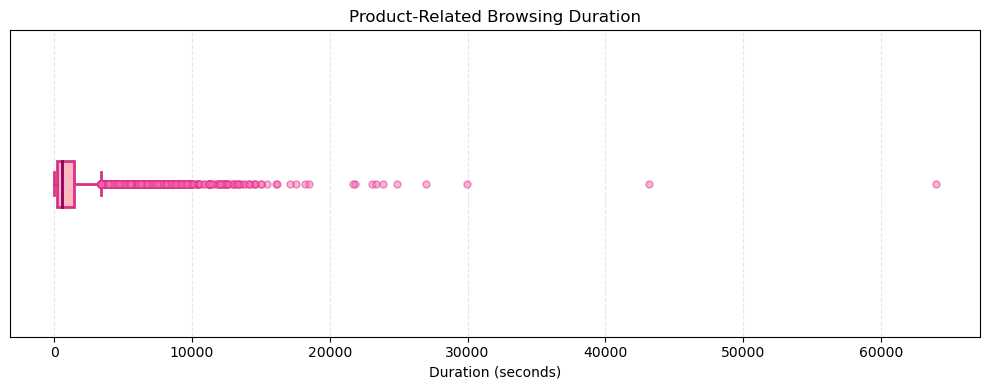

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4), facecolor="white")

plt.boxplot(
    df["ProductRelated_Duration"],
    vert=False,
    patch_artist=True,
    showfliers=True,
    boxprops=dict(facecolor="#ffb6c1", color="#d63384", linewidth=2),
    whiskerprops=dict(color="#d63384", linewidth=2),
    capprops=dict(color="#d63384", linewidth=2),
    medianprops=dict(color="#8b005d", linewidth=2),
    flierprops=dict(
        marker='o',
        markerfacecolor="#ff69b4",
        markeredgecolor="#d63384",
        markersize=5,
        alpha=0.5
    )
)

plt.title("Product-Related Browsing Duration")
plt.xlabel("Duration (seconds)")
plt.yticks([])
plt.gca().set_facecolor("white")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Outlier Analysis:
- **Ranges:** The `ProductRelated_Duration` variable ranges from 0 to approximately 63,974 seconds. This large range suggests that some shopping sessions have considerably longer browsing durations than others.

- **Quantiles:** The median duration is approximately 599 seconds, with 50% of observations falling between 184 and 1,464 seconds. The 95th percentile is approximately 4,300 seconds, while the 99th percentile is approximately 8,701 seconds. The maximum is significantly higher than these values, suggesting the presence of extreme outliers.

- **Boxplot**: The boxplot confirms a strongly right-skewed distribution, with most sessions concentrated at lower browsing durations. Numerous observations fall beyond the upper whisker, including several extreme values reaching approximately 64,000 seconds.

The above checks confirm the presence of outliers. I will also check the other variable values at the maximum `ProductRelated_Duration` value.

In [19]:
df.loc[df["ProductRelated_Duration"].idxmax()]

Administrative                             5
Administrative_Duration              3398.75
Informational                              6
Informational_Duration              2549.375
ProductRelated                           449
ProductRelated_Duration          63973.52223
BounceRates                         0.000764
ExitRates                           0.027701
PageValues                               0.0
SpecialDay                               0.0
Month                                    Dec
OperatingSystems                           2
Browser                                    2
Region                                     1
TrafficType                                2
VisitorType                Returning_Visitor
Weekend                                False
Revenue                                False
Name: 8071, dtype: object

This session recorded approximately 63,974 seconds of product-related browsing and 449 product-related page views, compared with a median of 18 pages across the dataset. It also included administrative and informational browsing activity.

The high number of page views suggests that the extreme duration may be associated with unusually extensive browsing activity. However, its accuracy cannot be confirmed from the available data.

Therefore, this observation will be retained for now, as there is insufficient evidence to classify it as an error.

Next, I will follow the same approach for the `ProductRelated` variable.

In [20]:
df["ProductRelated"].quantile([0.25, 0.50, 0.75, 0.95, 0.99, 1.00])

0.25      7.0
0.50     18.0
0.75     38.0
0.95    109.0
0.99    221.0
1.00    705.0
Name: ProductRelated, dtype: float64

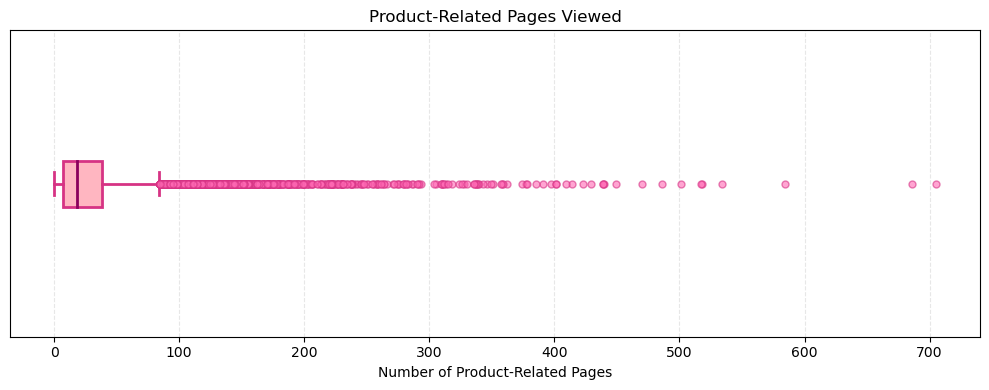

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4), facecolor="white")

plt.boxplot(
    df["ProductRelated"],
    vert=False,
    patch_artist=True,
    showfliers=True,
    boxprops=dict(facecolor="#ffb6c1", color="#d63384", linewidth=2),
    whiskerprops=dict(color="#d63384", linewidth=2),
    capprops=dict(color="#d63384", linewidth=2),
    medianprops=dict(color="#8b005d", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="#ff69b4",
        markeredgecolor="#d63384",
        markersize=5,
        alpha=0.6
    )
)

plt.title("Product-Related Pages Viewed")
plt.xlabel("Number of Product-Related Pages")
plt.yticks([])

plt.gca().set_facecolor("white")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:
df.loc[df["ProductRelated"].idxmax()]

Administrative                            17
Administrative_Duration          2629.253968
Informational                             24
Informational_Duration           2050.433333
ProductRelated                           705
ProductRelated_Duration          43171.23338
BounceRates                         0.004851
ExitRates                           0.015431
PageValues                          0.763829
SpecialDay                               0.0
Month                                    May
OperatingSystems                           2
Browser                                    2
Region                                     1
TrafficType                               14
VisitorType                Returning_Visitor
Weekend                                 True
Revenue                                False
Name: 5152, dtype: object

Outlier Analysis

- **Ranges:** The `ProductRelated` variable ranges from 0 to 705 product-related pages viewed. The maximum is considerably higher than the median of 18, suggesting that some sessions involve unusually high browsing activity.

- **Quantiles:** The middle 50% of sessions contain between 7 and 38 product-related page views. The 95th percentile is 109 pages, while the 99th percentile is 221 pages. The maximum of 705 is substantially higher, indicating the presence of extreme values.

- **Boxplot:** The boxplot shows a strongly right-skewed distribution, with most observations concentrated at lower page counts. Numerous observations fall beyond the upper whisker, including several sessions with more than 400 product-related page views.

- **Checking Maximum Value:** The observation with the highest page count (index 5152) was examined. This session recorded 705 product-related page views and approximately 43,171 seconds (12 hours) of product-related browsing. It also contained substantial administrative and informational browsing activity. This suggests that the unusually high page count may be associated with extensive browsing rather than an isolated recording error.


The range, quantiles and boxplot all indicate the presence of unusually high product-related page counts. However, these observations are not necessarily invalid. Therefore, the outliers will be retained at this stage, as there is insufficient evidence to justify removing them.

Next, I will do the same for `PageValues`.

In [23]:
df["PageValues"].quantile([0.25, 0.5, 0.75, 0.99, 1.00])

0.25      0.000000
0.50      0.000000
0.75      0.000000
0.99     85.498490
1.00    361.763742
Name: PageValues, dtype: float64

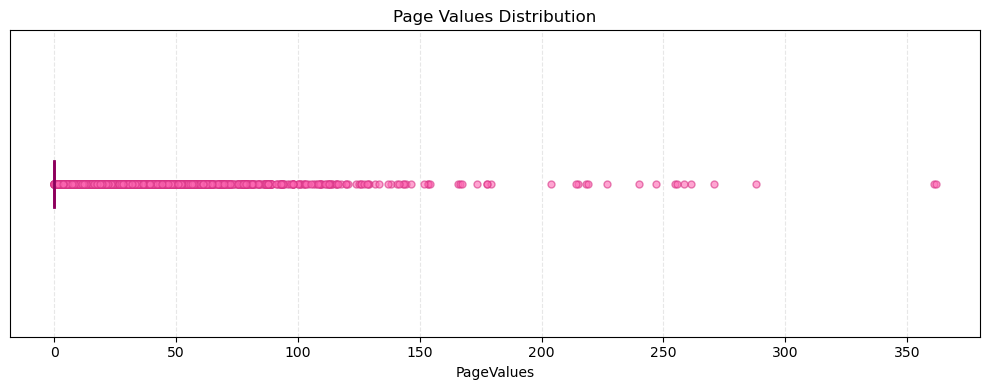

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4), facecolor="white")

plt.boxplot(
    df["PageValues"],
    vert=False,
    patch_artist=True,
    showfliers=True,
    boxprops=dict(facecolor="#ffb6c1", color="#d63384", linewidth=2),
    whiskerprops=dict(color="#d63384", linewidth=2),
    capprops=dict(color="#d63384", linewidth=2),
    medianprops=dict(color="#8b005d", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="#ff69b4",
        markeredgecolor="#d63384",
        markersize=5,
        alpha=0.6
    )
)

plt.title("Page Values Distribution")
plt.xlabel("PageValues")
plt.yticks([])

plt.gca().set_facecolor("white")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [25]:
df.loc[df["PageValues"].idxmax()]

Administrative                       3
Administrative_Duration           37.5
Informational                        0
Informational_Duration             0.0
ProductRelated                      18
ProductRelated_Duration          607.5
BounceRates                        0.0
ExitRates                     0.010526
PageValues                  361.763742
SpecialDay                         0.0
Month                              Nov
OperatingSystems                     2
Browser                              2
Region                               3
TrafficType                          2
VisitorType                New_Visitor
Weekend                          False
Revenue                           True
Name: 9239, dtype: object

Outlier Analysis

- **Ranges:** The PageValues variable ranges from 0 to approximately 361.76, with a mean of 5.89 and a median of 0. The large difference between the mean and median suggests a strongly right-skewed distribution, where most sessions have low values and a smaller number have considerably higher values.

- **Quantiles:** The 25th, 50th and 75th percentiles are all 0, indicating that at least 75% of shopping sessions have a PageValues value of zero. The 99th percentile is approximately 85.50, while the maximum is 361.76, over four times higher. This suggests the presence of extreme values in the upper end of the distribution.

- **Boxplot:** The boxplot confirms that the distribution is highly concentrated at zero, with numerous positive values extending towards the maximum of 361.76. Since the interquartile range (IQR) is zero, the box appears as a single line at zero. Using the standard 1.5 × IQR rule, all positive values are flagged as potential outliers. However, this rule is less informative for a variable with so many zero values, and the flagged observations should not automatically be considered errors.

- **Checking Maximum Value:** This session recorded a PageValues value of 361.76 and resulted in a purchase. The visitor viewed 18 product-related pages and spent approximately 608 seconds browsing them. Both values are close to the dataset medians of 18 pages and 599 seconds. Unlike the extreme observations identified in `ProductRelated` and `ProductRelated_Duration`, this session did not involve unusually extensive browsing activity. Therefore, the unusually high `PageValues` value cannot be explained simply by a large number of pages viewed or a long browsing duration.

The range, quantile analysis and boxplot all indicate that PageValues has a strongly right-skewed distribution, with many zero values and a smaller number of extreme positive observations. Although these observations are statistically unusual, there is insufficient evidence to classify them as recording errors. Therefore, no outliers have been removed or modified at this stage.

Also since `PageValues` may be closely associated with purchasing behaviour, its availability at prediction time will need to be considered during the data leakage investigation before it is included in the preprocessing pipeline.

Next, we want to check the rest of the numerical values.

In [26]:
columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "BounceRates",
    "ExitRates"
]

df[columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200


Outlier analysis

The remaining numerical variables were examined using summary statistics to identify potentially unusual values.

**`Administrative` and `Administrative_Duration`:** Both variables show evidence of right-skewed distributions. `Administrative` has a median of 1 and a maximum of 27, while `Administrative_Duration` has a median of 7.5 seconds and a maximum of approximately 3,399 seconds. These differences suggest the presence of unusually high observations.

**`Informational` and `Informational_Duration`:** Both variables have 25th, 50th and 75th percentiles of zero, indicating that at least 75% of sessions have no recorded informational page views or informational browsing duration. However, their maximum values are 24 pages and approximately 2,549 seconds, respectively. This suggests that a smaller number of sessions contain substantially more informational browsing activity.

**`BounceRates` and `ExitRates`:** Both variables are concentrated towards the lower end of their observed ranges. `BounceRates` has a median of approximately 0.0031, while `ExitRates` has a median of approximately 0.0252. Both have maximum values of 0.2. Although their distributions are right-skewed, there is no clear evidence of invalid values from these summary statistics.

Several numerical variables contain potentially unusual observations, particularly the browsing duration and page count features. However, these values are not necessarily errors. No outliers have been removed or modified at this stage, as there is insufficient evidence to justify doing so.

Next, I will examine the target variable.

In [27]:
df["Revenue"].value_counts(normalize=True) * 100

False    84.525547
True     15.474453
Name: Revenue, dtype: float64

These results show that 84.5% of sessions did not results in a sale while only 15.5% of sessions did result in a sale. 
This shows that there is a clear class imbalance with significantly more non-purchasing sessions than purchasing sessions.
No changes have been made at this stage.

Now, I want to check for potential leakage. 

Starting with `PageValues` and I will compare this against `Revenue`.

In [28]:
df.groupby("Revenue")["PageValues"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,1.975998,9.072424,0.0,0.000000,0.000000,0.000000,246.758590
True,1908.0,27.264518,35.191954,0.0,3.641144,16.758134,38.897742,361.763742


The results show a substantial difference between purchasing and non-purchasing sessions. Sessions that resulted in a purchase had a mean `PageValues` of approximately 27.26 and a median of 16.76, compared with a mean of 1.98 and a median of 0 for sessions that did not result in a purchase.

This indicates a strong association between `PageValues` and purchasing outcomes. 
Since the exact timing and calculation of this feature in relation to the current sessions outcomes have not been established, `PageValues` is a potential lealage risk.

Next I will check `ExitRates`.

In [29]:
df.groupby("Revenue")["ExitRates"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,0.047378,0.051231,0.0,0.015560,0.028571,0.053846,0.2
True,1908.0,0.019555,0.016463,0.0,0.009521,0.016000,0.025000,0.2


The results showed that non-purchasing sessions had a higher mean exit rate of approximately 0.0474, compared with 0.0196 for purchasing sessions. The median exit rate was also higher for non-purchasing sessions (0.0286) than purchasing sessions (0.0160).

This suggests that lower exit rates are associated with sessions that result in a purchase. However, the distributions overlap, indicating that `ExitRates` does not perfectly distinguish between purchasing and non-purchasing sessions.

Although `ExitRates` is associated with the target variable, this does not necessarily indicate data leakage. Leakage depends on whether the feature would be available at the time a prediction is made.

`ExitRates` will be provisionally retained as a potential input feature, subject to confirming that it can be calculated without using information from after the intended prediction point.

Next, I will check `ProductRelated_Duration`.

In [30]:
df.groupby("Revenue")["ProductRelated_Duration"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,1069.987809,1803.797757,0.0,151.00000,510.19000,1331.816667,63973.52223
True,1908.0,1876.209615,2312.214392,0.0,541.90625,1109.90625,2266.011310,27009.85943


Purchasing sessions had a higher mean product-related browsing duration of approximately 1,876 seconds, compared with 1,070 seconds for non-purchasing sessions. The median was also higher for purchasing sessions (1,110 seconds) than non-purchasing sessions (510 seconds).

This suggests that longer product-related browsing durations are associated with a greater likelihood of purchasing. However, both groups contain extreme observations, and the longest recorded duration occurred in a non-purchasing session.

A potential data leakage concern arises from the timing of the prediction. If the model is intended to predict a purchase during an active browsing session, the final browsing duration may not yet be available.

Therefore, `ProductRelated_Duration` will be considered a potentially useful predictor, but its inclusion will depend on whether the recorded duration is available at the intended prediction point.

**Potenial Leakage Summary**

The dataset was examined for potential data leakage, focusing on whether input features would be available at the time a prediction is made.

`PageValues` was identified as a potential leakage risk because its calculation is related to e-commerce transaction value. Purchasing sessions had considerably higher values than non-purchasing sessions, although this association alone does not confirm leakage.

`ExitRates` was also investigated. Non-purchasing sessions generally had higher exit rates, but whether this feature introduces leakage depends on how and when the page-level statistics were calculated.

The browsing duration variables, including `ProductRelated_Duration`, may also present a risk because their final values may only be known after a session has progressed or ended.

Since the dataset contains session-level summaries rather than time-specific snapshots, it is not possible to establish whether every recorded feature would be available during a live prediction.

Therefore, feature selection during preprocessing will consider prediction-time availability. `PageValues` will be excluded from the initial modelling features as a precaution, while the limitations of using completed-session information will be acknowledged.

The resulting model will be evaluated as an analysis of recorded session behaviour rather than a verified real-time purchasing prediction system.

**Data Cleaning and Preprocessing**

In this section, I will prepare the dataset for machine learning using the findings from the data audit.

Firstly, I will remove the 125 exact duplicate records identified during the audit. No missing-value imputation will be required, as no missing values were detected. I will retain the numerical outliers, as there is insufficient evidence to classify them as errors.

Next, I will separate the input features from the target variable, `Revenue`. I will exclude `PageValues` from the initial feature set due to potential data leakage concerns. The remaining 16 features will be divided into numerical and categorical variables.

I will then use `StandardScaler` to standardise the numerical features and `OneHotEncoder` to encode the categorical features. These transformations will be combined using `ColumnTransformer` and a scikit-learn `Pipeline`.

Finally, I will split the dataset into training and testing sets using an 80/20 stratified split. The preprocessing transformations will be fitted using the training data only to prevent data leakage.

The aim of this section is to create a reproducible preprocessing workflow that prepares the dataset for model training and evaluation.

In [45]:
df_clean = df.copy() # This creates a copy of the original dataset
df_clean = df_clean.drop_duplicates() # This removes the duplicates from the copied dataset

df_clean.shape 

(12205, 18)

In [32]:
X = df_clean.drop(columns=["Revenue", "PageValues"]) # This will separate the input features from the target variable
y = df_clean["Revenue"] # This selectes the target variable

print("Features:", X.shape)
print("Target:", y.shape)

Features: (12205, 16)
Target: (12205,)


In [33]:
# Identify numerical features
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

# Identify categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Check the number of features in each group
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))


Numerical features: 9
Categorical features: 7
Total features: 16


The 16 input features were divided into numerical and categorical groups based on their meaning rather than solely their Pandas data types.

Nine features were identified as numerical, including `PageValues`, `BrowsingDurations`, `BounceRates`, `ExitRates` and `SpecialDay`.

Seven features were identified as categorical, including `Month`, `VisitorType`, `Weekend` and the integer-coded variables `OperatingSystems`, `Browser`, `Region` and `TrafficType`.

This distinction is important because numerical features may require scaling, while categorical features require suitable encoding before they can be used by machine learning models.

In [46]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (9764, 16)
Testing features: (2441, 16)
Training target: (9764,)
Testing target: (2441,)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create a preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

preprocessor


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'BounceRates', 'ExitRates', 'SpecialDay']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Month', 'OperatingSystems', 'Browser',
                                  'Region', 'TrafficType', 'VisitorType',
                                  'Weekend'])])

In [36]:
from sklearn.pipeline import Pipeline

# Create a preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

# Display the pipeline
preprocessing_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Administrative',
                                                   'Administrative_Duration',
                                                   'Informational',
                                                   'Informational_Duration',
                                                   'ProductRelated',
                                                   'ProductRelated_Duration',
                                                   'BounceRates', 'ExitRates',
                                                   'SpecialDay']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Month', 'OperatingSystems',
                                                   'Browser', 'Region',
                                                   'TrafficType', 'VisitorType',
                                                   'Weekend'])]))])

A scikit-learn `Pipeline` was created to organise the preprocessing steps into a reproducible workflow.

The pipeline contains the previously defined `ColumnTransformer`, which applies `StandardScaler` to numerical features and `OneHotEncoder` to categorical features.

The pipeline has not yet been fitted. Any learned preprocessing parameters will be fitted using the training data only to prevent data leakage.

In [37]:
# Fit the preprocessing pipeline on training data only
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Transform the test data using the fitted pipeline
X_test_processed = preprocessing_pipeline.transform(X_test)

# Check the resulting dimensions
print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)


Processed training data: (9764, 73)
Processed testing data: (2441, 73)


The preprocessing pipeline was fitted using the training data only, ensuring that scaling parameters and categorical mappings were learned without using the test set.

The fitted pipeline was then applied to the test data using `transform()`, without refitting the preprocessing steps.

The resulting datasets were examined to confirm that preprocessing completed successfully and that the training and testing sets contained the same number of transformed features.

**Baseline Model and Evaluation**

In this section, I will create a baseline model to establish a reference point for evaluating future machine learning models.

I will use a majority-class `DummyClassifier`. This classifier will always predict the most common target class in the training data, without learning relationships between browsing behaviour and purchasing outcomes.

As the target variable, `Revenue`, is imbalanced, I expect the classifier to predict `Revenue = False` for every shopping session.

I will evaluate the baseline model using accuracy, precision, recall, F1-score and a confusion matrix. These metrics will help me understand the model's performance and demonstrate why accuracy alone may be misleading when working with imbalanced classification data.

The aim of this section is to establish a baseline against which Logistic Regression, K-Nearest Neighbours and Decision Tree models can be compared in the next milestone.

In [38]:
from sklearn.dummy import DummyClassifier

# Create a majority-class baseline model
dummy_model = DummyClassifier(strategy="most_frequent")

# Fit the model using the training data
dummy_model.fit(X_train, y_train)

# Predict the purchase outcome for the test data
y_pred_dummy = dummy_model.predict(X_test)

# Display the first 10 predictions
print(y_pred_dummy[:10])

[False False False False False False False False False False]


The classifier always predicts the most frequent target class in the training data, without learning relationships between browsing behaviour and purchasing outcomes.

Next, I want to evaluate the baseline using accuracy.

In [39]:
from sklearn.metrics import accuracy_score

# Calculate the accuracy of the baseline model
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

# Display the accuracy
print("Baseline Accuracy:", dummy_accuracy)

Baseline Accuracy: 0.8435067595247849


The majority-class Dummy Classifier achieved an accuracy of approximately 84.35% on the test dataset.

Although this appears relatively high, the result is explained by the imbalance in the target variable. The classifier always predicts Revenue = False, which represents the majority of shopping sessions.

As a result, the model correctly identifies non-purchasing sessions but fails to identify any purchasing sessions.

This demonstrates that accuracy alone can be misleading when evaluating models on imbalanced datasets. Additional metrics, including precision, recall and F1-score, are required to assess the model's ability to identify purchasing sessions.

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate evaluation metrics for the purchasing class
dummy_precision = precision_score(y_test, y_pred_dummy, zero_division=0)
dummy_recall = recall_score(y_test, y_pred_dummy, zero_division=0)
dummy_f1 = f1_score(y_test, y_pred_dummy, zero_division=0)

print("Baseline Precision:", dummy_precision)
print("Baseline Recall:", dummy_recall)
print("Baseline F1-score:", dummy_f1)

Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0


The precision was reported as zero as the model never predicted a purchasing session. The recall of zero confirms that none of the actual purchasing sessions were correctly identified, while the F1-score also reflects this failure to identify the positive class.

Although the classifier achieved 84.35% accuracy, these results show that it is ineffective at predicting purchases. This demonstrates the limitations of accuracy when evaluating imbalanced classification datasets.

The results provide a baseline against which future models, including Logistic Regression, K-Nearest Neighbours and Decision Trees, can be compared.

In [41]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
dummy_cm = confusion_matrix(y_test, y_pred_dummy)

# Display the result
print(dummy_cm)

[[2059    0]
 [ 382    0]]


The confusion matrix was used to examine the predictions made by the majority-class Dummy Classifier.

The model correctly classified 2,059 non-purchasing sessions (true negatives) but incorrectly classified all 382 purchasing sessions as non-purchasing (false negatives).

There were no true positives or false positives because the classifier always predicted Revenue = False.

These results confirm that the baseline model is unable to identify purchasing sessions. Although it achieved an accuracy of 84.35%, it failed to detect any of the positive class.

This demonstrates why accuracy alone is insufficient for evaluating this imbalanced classification problem. Future models will need to improve their ability to identify purchasing sessions, particularly by achieving higher recall and F1-scores.

## Milestone 2 — Conclusion

This milestone focused on preparing the Online Shoppers Purchasing Intention dataset and establishing a baseline model for predicting whether shopping sessions result in purchases.

**Data Audit and Preprocessing**

The original dataset contained 12,330 observations and 18 variables. The audit identified no missing values, 125 exact duplicate records, several numerical outliers and an imbalanced target variable.

The duplicate records were removed, leaving 12,205 observations. The `PageValues` feature was excluded from the initial model due to potential data leakage concerns.

The remaining 16 features were divided into numerical and categorical groups. `StandardScaler` and `OneHotEncoder` were applied using a `ColumnTransformer` and preprocessing pipeline. An 80/20 stratified train/test split was used, with preprocessing fitted on training data only.

**Baseline Model and Evaluation**

A majority-class Dummy Classifier was implemented using the methods covered in Week 4.

The classifier achieved an accuracy of 84.35%. However, precision, recall and F1-score for the purchasing class were all zero.

The confusion matrix showed that the model correctly classified 2,059 non-purchasing sessions but failed to identify any of the 382 purchasing sessions.

These results demonstrate that accuracy alone is insufficient when evaluating this imbalanced classification problem.

**Limitations and Next Steps**

The dataset contains potentially extreme observations, an imbalanced target distribution and session-level features that may not all be available during a real-time prediction.

Logistic Regression, K-Nearest Neighbours and Decision Tree models will be investigated and compared with the baseline using the same evaluation design.

Particular attention will be given to recall and F1-score for the purchasing class, as identifying purchasing sessions is an important objective of the project.